In [50]:
import textwrap

import fcbench
import numpy as np
import pandas as pd
import xarray as xr

from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec
from tqdm import tqdm

In [2]:
ds_500hPa_mean = xr.open_dataset("data/500hPa-mean.nc", chunks={})
ds_500hPa_spread = xr.open_dataset("data/500hPa-spread.nc", chunks={})

In [3]:
ds_1000hPa_mean = xr.open_dataset("data/1000hPa-mean.nc", chunks={})
ds_1000hPa_spread = xr.open_dataset("data/1000hPa-spread.nc", chunks={})

In [4]:
ds_depth_mean = xr.open_dataset("data/depth-mean.nc", chunks={})
ds_depth_spread = xr.open_dataset("data/depth-spread.nc", chunks={})

In [5]:
ds_surface_mean = xr.open_dataset("data/surface-mean.nc", chunks={})
ds_surface_spread = xr.open_dataset("data/surface-spread.nc", chunks={})

In [6]:
ds_mean = xr.Dataset({
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (500 hPa)") for v, da in ds_500hPa_mean.items()},
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (1000 hPa)") for v, da in ds_1000hPa_mean.items()},
    **ds_depth_mean,
    **ds_surface_mean,
})
ds_spread = xr.Dataset({
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (500 hPa)") for v, da in ds_500hPa_spread.items()},
    **{v: da.squeeze().drop_vars("pressure_level").assign_attrs(long_name=f"{da.long_name} (1000 hPa)") for v, da in ds_1000hPa_spread.items()},
    **ds_depth_spread,
    **ds_surface_spread,
})

In [7]:
list(ds_mean)

['z',
 'q',
 'r',
 'swvl1',
 'siconc',
 'lai_hv',
 'sp',
 'sd',
 'lsp',
 'cp',
 'tcc',
 'u10',
 'v10',
 't2m',
 'ssrd',
 'src',
 'tco3',
 'cbh']

In [56]:
def plot_ensemble_mean_spread(key, ax, lax, sample=slice(None)):
    mean = ds_mean[key]
    spread = ds_spread[key]

    abs_cns, abs_prg = np.nanquantile(spread.where(spread > 0.0), [0.0, 0.01])

    abs_mean = np.abs(mean)
    rel = spread.where(abs_mean > 0.0) / abs_mean.where(abs_mean > 0.0)
    rel_cns, rel_prg = np.nanquantile(rel.where(rel > 0.0), [0.0, 0.01])

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    ax.set_xlabel(f"mean [{mean.units}]")
    ax.set_ylabel(f"spread [{spread.units}]")

    if key in ():
        ax.set_xscale("log")
        ax.set_yscale("log")

    handles = []

    for (year, month), colour in zip(months, colours):
        handles.append(ax.scatter(
            mean.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            spread.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            s=1, label=f"{year}/{month:02}", edgecolor="none", marker=".", c=colour,
        ))

    legends = []

    legends.append(ax.axhline(abs_cns, c="red", ls="--", label=f"$abs_{{cns}} = {abs_cns:.03}$"))
    legends.append(ax.axhline(abs_prg, c="red", ls=":", label=f"$abs_{{prg}} = {abs_prg:.03}$"))

    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    rlim = sorted([xlim[0], 0.0, xlim[1]])

    legends.extend(ax.plot(rlim, np.array(rlim) * rel_cns * np.sign(rlim), c="blue", ls="--", label=f"$rel_{{cns}} = {rel_cns:.03}$"))
    legends.extend(ax.plot(rlim, np.array(rlim) * rel_prg * np.sign(rlim), c="blue", ls=":", label=f"$rel_{{prg}} = {rel_prg:.03}$"))

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    lax.axis("off")
    lax.legend(handles=legends, loc="center")

    return handles

/Users/junityre/era5-ensemble/.venv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
/Users/junityre/era5-ensemble/.venv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1545: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(
100%|███████████████████████████████████████████████████████████████████████████████| 18/18 [02:31<00:00,  8.43s/it]


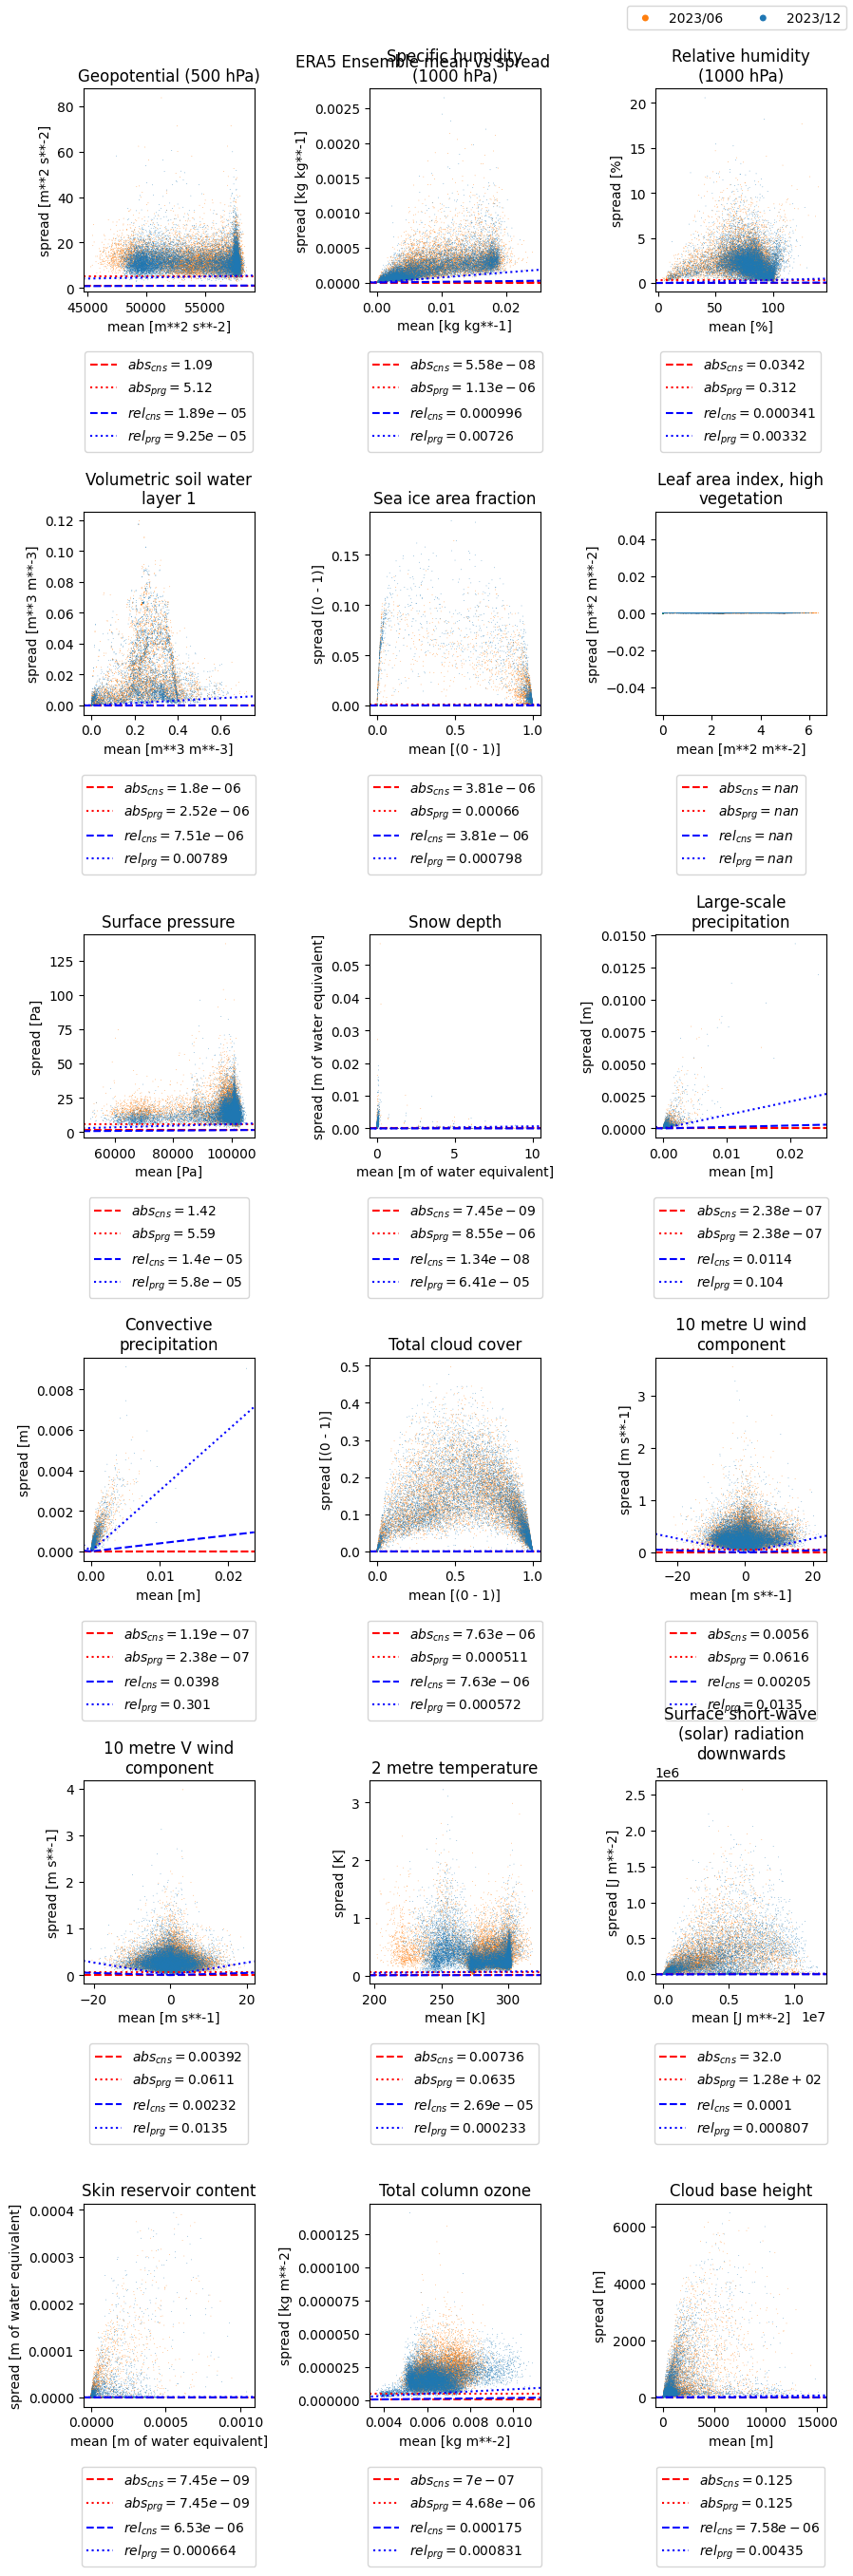

In [59]:
fig = plt.figure(figsize=(9, 27))
fig.suptitle("ERA5 Ensemble mean vs spread")

gs = GridSpec(18, 6, figure=fig)

for i, key in enumerate(tqdm(ds_mean)):
    ax = fig.add_subplot(gs[(i//3)*3:(i//3)*3+2, (i%3)*2:(i%3)*2+2])
    lax = fig.add_subplot(gs[(i//3)*3+2, (i%3)*2:(i%3)*2+2])
    handles = plot_ensemble_mean_spread(key, ax, lax, sample=slice(0, None, 5000))

fig.legend(handles=handles, loc="upper right", ncols=len(handles), markerscale=10)

fig.tight_layout()
plt.show()

In [10]:
def plot_bitinformation(key, ax):
    mean = ds_mean[key]

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    
    ax.set_xlabel("bit index")
    ax.set_xticks([0, 8.5, 31])
    ax.set_ylabel("information [bits]")

    handles = []

    for (year, month), colour in zip(months, colours):
        bit_information = fcbench.metrics.BitInformation.bit_information(
            mean.sel(valid_time=f"{year}-{month:02}"),
            set_zero_insignificant_confidence=0.99,
        )

        p99 = np.searchsorted(np.cumsum(bit_information) / np.sum(bit_information), 0.99)
        ax.axvline(p99, c=colour, ls=":")
        
        handles.extend(ax.plot(
            np.arange(32), bit_information, label=f"{year}/{month:02}", c=colour,
        ))

    ax.axvline(8.5, c="black", ls="--")

    return handles

100%|███████████████████████████████████████████████████████████████████████████████| 18/18 [01:13<00:00,  4.07s/it]


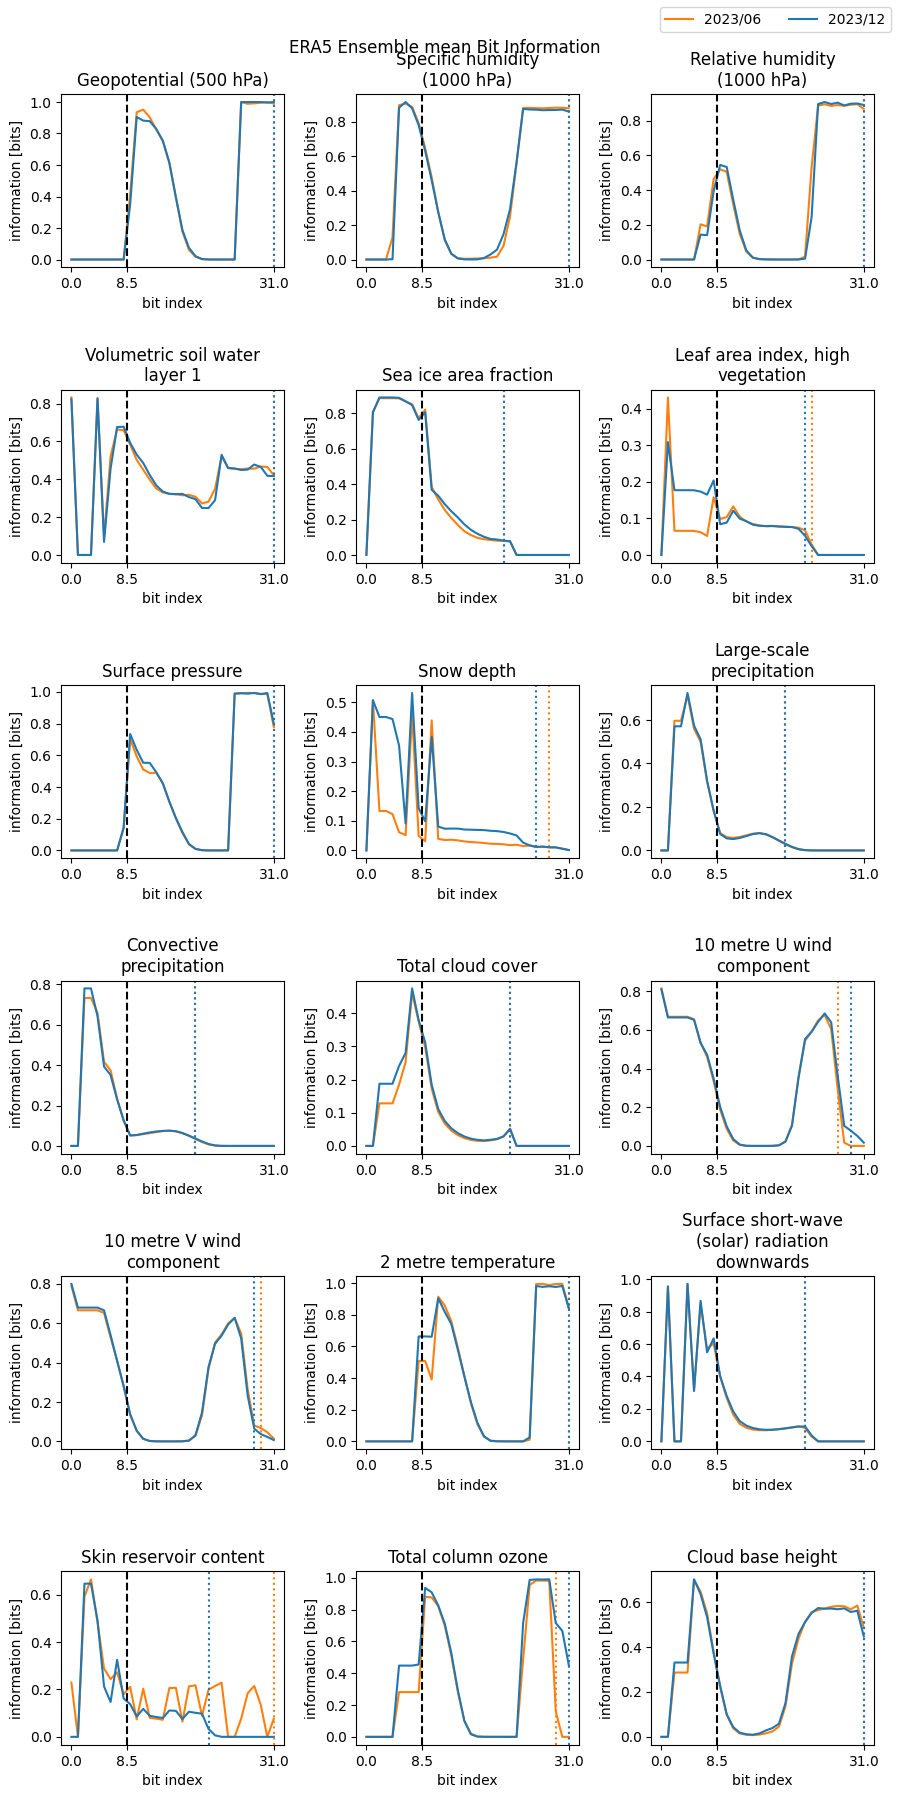

In [11]:
fig, axs = plt.subplots(6, 3, figsize=(9, 18))
fig.suptitle("ERA5 Ensemble mean Bit Information")

for key, ax in zip(tqdm(ds_mean), axs.flatten()):
    handles = plot_bitinformation(key, ax)

fig.legend(handles=handles, loc="upper right", ncols=len(handles))

fig.tight_layout()
plt.show()

In [40]:
ds_XhPa_mean = xr.open_dataset("data/XhPa-mean.nc", chunks={})
ds_XhPa_spread = xr.open_dataset("data/XhPa-spread.nc", chunks={})

In [45]:
for key in ds_XhPa_mean:
    print(f"=== {ds_XhPa_mean[key].long_name} ===")

    mean = ds_XhPa_mean[key]
    spread = ds_XhPa_spread[key]
    
    for p in tqdm(mean.pressure_level.values):
        pmean = mean.sel(dict(pressure_level=p))
        pspread = spread.sel(dict(pressure_level=p))
        
        abs_cns, abs_prg = np.nanquantile(pspread.where(pspread > 0.0), [0.0, 0.01])
        
        abs_mean = np.abs(pmean)
        rel = pspread.where(abs_mean > 0.0) / abs_mean.where(abs_mean > 0.0)
        rel_cns, rel_prg = np.nanquantile(rel.where(rel > 0.0), [0.0, 0.01])
    
        print(p, abs_cns, abs_prg, rel_cns, rel_prg)

=== Geopotential ===


 25%|████████████████████▎                                                            | 1/4 [00:07<00:21,  7.08s/it]

1000.0 0.9873207211494446 4.679173469543457 0.00041227086330763996 0.0024945810437202454


 50%|████████████████████████████████████████▌                                        | 2/4 [00:14<00:14,  7.22s/it]

850.0 1.1716346740722656 4.889779090881348 7.870088302297518e-05 0.00033716409758199005


...

850.0 0.06157151237130165 0.40573257207870483 0.0006159079493954778 0.0045026871375739574


 75%|████████████████████████████████████████████████████████████▊                    | 3/4 [00:22<00:07,  7.52s/it]

500.0 0.037726305425167084 0.25019800662994385 0.0007368582882918417 0.01268095726147294


100%|█████████████████████████████████████████████████████████████████████████████████| 4/4 [00:29<00:00,  7.41s/it]

50.0 0.0003068831283599138 0.001419018255546689 0.0025448815431445837 0.010628093034029007
